In [ ]:
from google.colab import files
uploaded = files.upload()

Saving UK_crop_climate_data.xlsx to UK_crop_climate_data (1).xlsx


In [ ]:
import pandas as pd
import io
df = pd.read_excel(io.BytesIO(uploaded['UK_crop_climate_data (1).xlsx']))

In [ ]:
df.shape

(600, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   year        600 non-null    int64  
 1   region      600 non-null    object 
 2   area        600 non-null    float64
 3   yield       600 non-null    float64
 4   production  600 non-null    float64
 5   crop_type   600 non-null    object 
 6   tas         600 non-null    float64
 7   tasmin      600 non-null    float64
 8   tasmax      600 non-null    float64
 9   sun         600 non-null    float64
 10  rainfall    600 non-null    float64
dtypes: float64(8), int64(1), object(2)
memory usage: 51.7+ KB


# Descriptive Statistics

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,600.0,2011.000000,7.217119,1999.000000,2005.000000,2011.000000,2.017000e+03,2.023000e+03
area,600.0,106347.535233,117364.358110,2562.040000,19471.072500,63573.775000,1.590807e+05,5.447565e+05
yield,600.0,6.396533,1.155582,3.400000,5.587500,6.125000,7.290000e+00,9.420000e+00
production,600.0,770625.228867,961638.382008,14636.280000,109459.347500,386489.345000,1.091873e+06,4.660686e+06
tas,600.0,10.016168,0.895936,7.354942,9.409607,10.109099,1.069400e+01,1.194225e+01
tasmin,600.0,6.175368,0.756317,3.686809,5.690013,6.212227,6.750384e+00,7.732032e+00
tasmax,600.0,13.869296,1.082398,11.022406,13.045498,14.041201,1.465825e+01,1.641440e+01
sun,600.0,1751.547051,604.532438,1266.935550,1457.677825,1539.441175,1.656837e+03,3.714621e+03
rainfall,600.0,976.525800,310.413609,453.030210,747.295563,912.896135,1.156260e+03,1.980521e+03


In [ ]:
df.sample(10)

,year,region,area,yield,production,crop_type,tas,tasmin,tasmax,sun,rainfall
110,2012,South East and London,19469.76,5.66,110192.24,oats,10.526598,6.556879,14.508905,3180.30448,1795.23630
419,2001,East Midlands,104527.00,5.41,565022.19,barley,9.508740,5.540795,13.485603,1500.37499,737.62124
565,2019,Eastern,199317.79,6.97,1389555.59,barley,10.766709,6.444659,15.111348,1739.04406,629.50585
77,2008,Eastern,9662.90,6.81,65778.94,oats,10.298678,6.254177,14.347859,1568.71132,684.73516
181,2021,Eastern,26123.82,5.19,135537.93,oats,10.422353,6.469650,14.377990,1502.27803,633.40029
284,2009,West Midlands,151420.98,7.40,1120871.17,wheat,9.812680,5.864716,13.763433,1489.69277,747.48053
10,2000,Yorkshire & The Humber,4969.62,4.82,23947.62,oats,9.209767,5.621809,12.822741,1358.45282,1131.14873
469,2007,Eastern,130674.22,5.60,731559.14,barley,10.771378,6.654928,14.901633,1573.90007,689.11463
78,2008,South East and London,22103.45,6.38,140912.91,oats,10.732562,6.758059,14.718685,3145.78380,1489.43280
349,2017,Eastern,455761.46,8.57,3905794.16,wheat,10.913158,6.889875,14.950562,1567.71559,602.78579


# EDA and Correlation Analysis

Descriptive Statistics for Numerical Variables:
                area       yield    production         tas      tasmin  \
count     600.000000  600.000000  6.000000e+02  600.000000  600.000000   
mean   106347.535233    6.396533  7.706252e+05   10.016168    6.175368   
std    117364.358110    1.155582  9.616384e+05    0.895936    0.756317   
min      2562.040000    3.400000  1.463628e+04    7.354942    3.686809   
25%     19471.072500    5.587500  1.094593e+05    9.409607    5.690013   
50%     63573.775000    6.125000  3.864893e+05   10.109099    6.212227   
75%    159080.672500    7.290000  1.091873e+06   10.694002    6.750384   
max    544756.500000    9.420000  4.660686e+06   11.942250    7.732032   

           tasmax          sun     rainfall  
count  600.000000   600.000000   600.000000  
mean    13.869296  1751.547051   976.525800  
std      1.082398   604.532438   310.413609  
min     11.022406  1266.935550   453.030210  
25%     13.045498  1457.677825   747.295563  
50%     1

Text(0.5, 1.0, 'Correlation Matrix of Yield and Climate Variables')

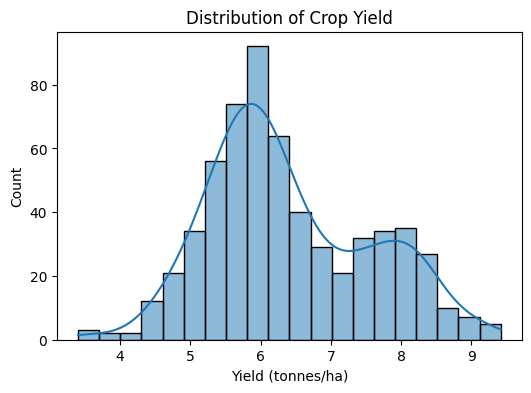

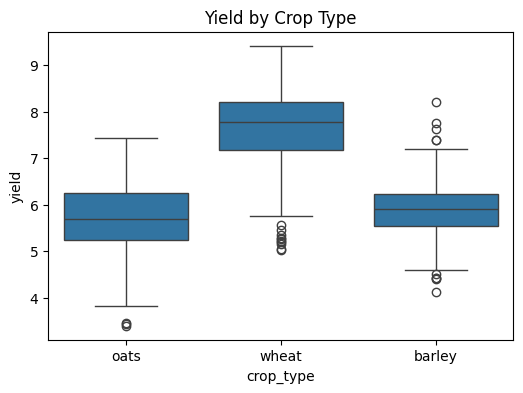

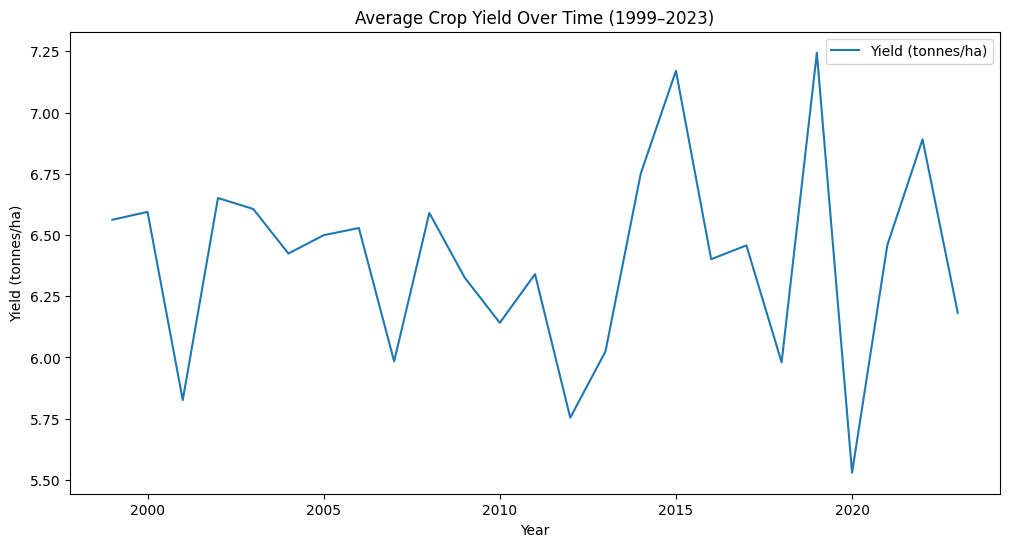

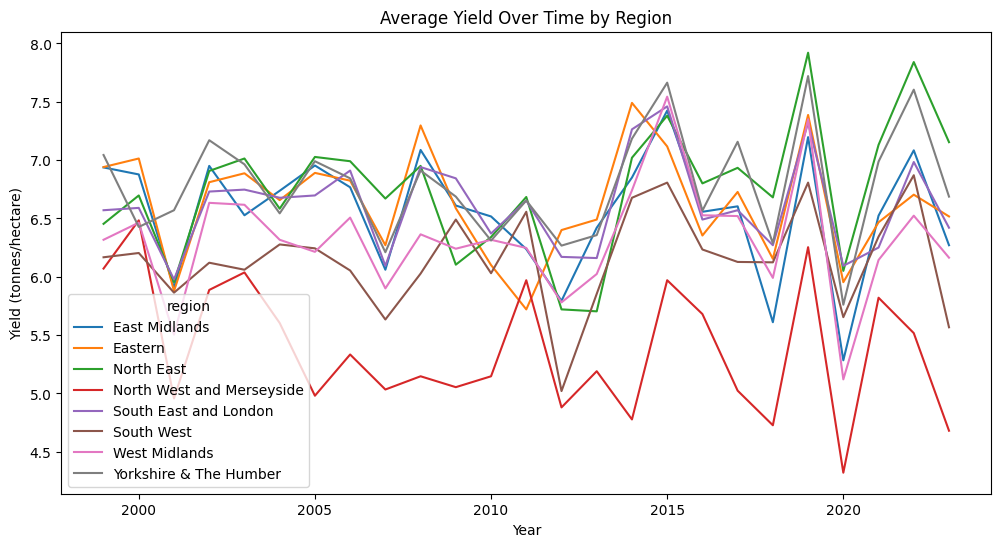

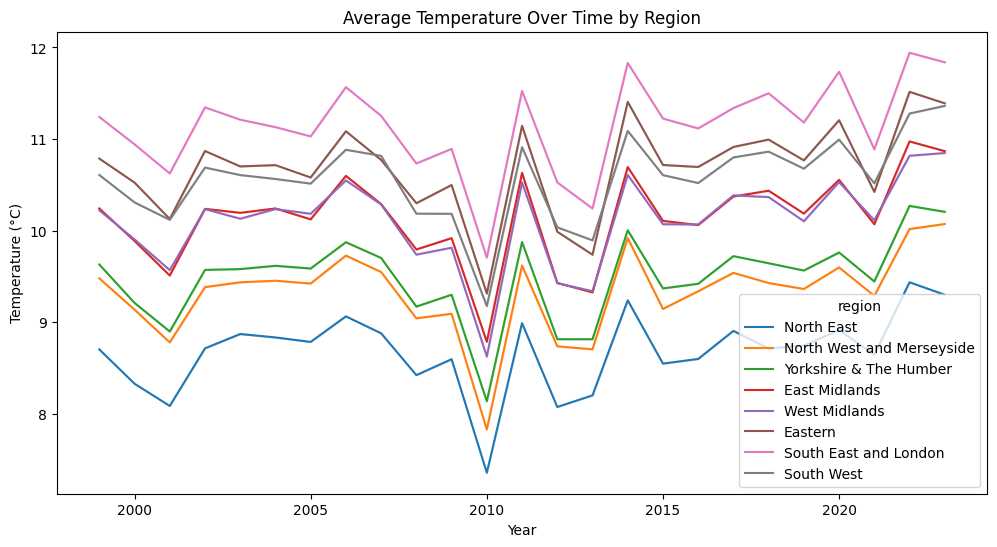

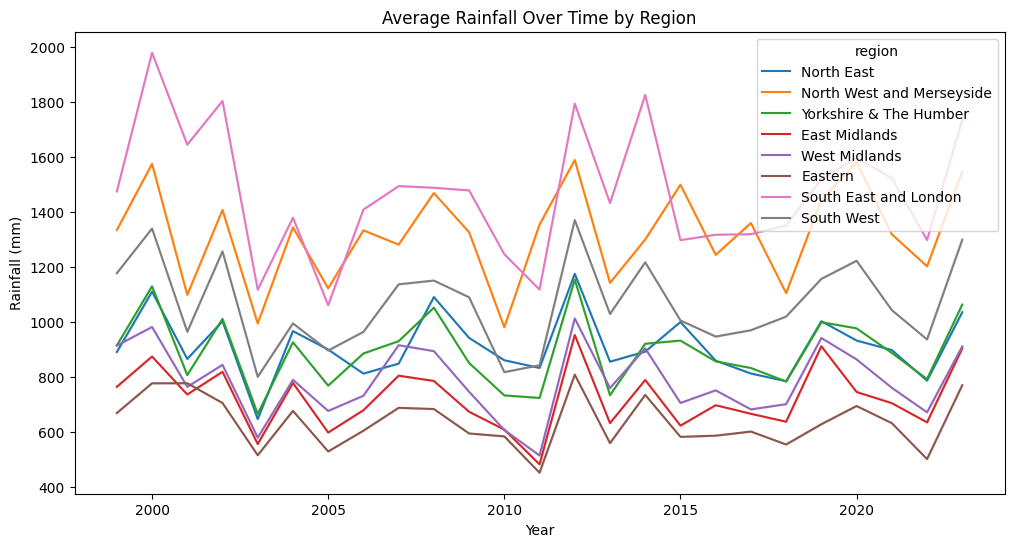

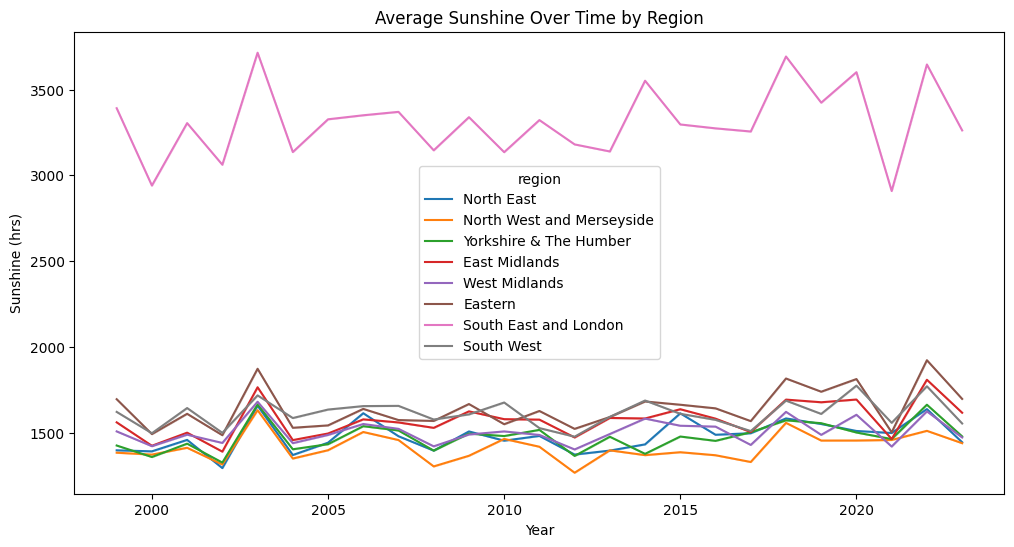

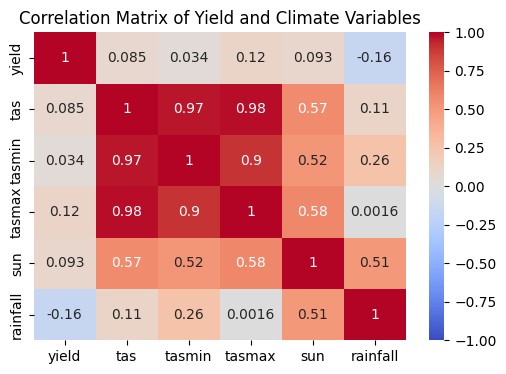

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns


# 1. Descriptive Statistics
# Numerical variables
numerical_cols = ['area', 'yield', 'production', 'tas', 'tasmin', 'tasmax', 'sun', 'rainfall']
desc_stats = df[numerical_cols].describe()
print("Descriptive Statistics for Numerical Variables:")
print(desc_stats)

# By crop_type
print("\nMean Yield by Crop Type:")
print(df.groupby('crop_type')['yield'].mean())

# By region
print("\nMean Temperature and Rainfall by Region:")
print(df.groupby('region')[['tas', 'rainfall']].mean())

# Categorical variables
print("\nCount of Records by Crop Type:")
print(df['crop_type'].value_counts())
print("\nCount of Records by Region:")
print(df['region'].value_counts())

# Visualizations
# Histogram of yield
plt.figure(figsize=(6, 4))
sns.histplot(df['yield'], bins=20, kde=True)
plt.title('Distribution of Crop Yield')
plt.xlabel('Yield (tonnes/ha)')
# plt.savefig('yield_histogram.png')
# plt.close()

# Boxplot of yield by crop_type
plt.figure(figsize=(6, 4))
sns.boxplot(x='crop_type', y='yield', data=df)
plt.title('Yield by Crop Type')
# plt.savefig('yield_boxplot_crop.png')
# plt.close()

# 2. Temporal Analysis
# Yearly averages for yield and tas
yearly_avg = df.groupby('year')[['yield', 'tas', 'rainfall']].mean().reset_index()

# Time-series plot for yield
plt.figure(figsize=(12, 6))
sns.lineplot(x='year', y='yield', data=yearly_avg, label='Yield (tonnes/ha)')
plt.title('Average Crop Yield Over Time (1999–2023)')
plt.xlabel('Year')
plt.ylabel('Yield (tonnes/ha)')
# plt.savefig('yield_timeseries.png')
# plt.close()

# Time-series plot for yield by region
plt.figure(figsize=(12, 6))
# Convert the Series to a DataFrame and reset the index
plot_data = df.groupby(['year', 'region'])['yield'].mean().reset_index()
sns.lineplot(x='year', y='yield', hue='region', data=plot_data)
plt.title('Average Yield Over Time by Region')
plt.xlabel('Year')
plt.ylabel('Yield (tonnes/hectare)')
# plt.savefig('tas_timeseries_region.png')
# plt.close()

# Time-series plot for tas by region
plt.figure(figsize=(12, 6))
sns.lineplot(x='year', y='tas', hue='region', data=df)
plt.title('Average Temperature Over Time by Region')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
# plt.savefig('tas_timeseries_region.png')
# plt.close()

# Time-series plot for rainfall by region
plt.figure(figsize=(12, 6))
sns.lineplot(x='year', y='rainfall', hue='region', data=df)
plt.title('Average Rainfall Over Time by Region')
plt.xlabel('Year')
plt.ylabel('Rainfall (mm)')
# plt.savefig('tas_timeseries_region.png')
# plt.close()

# Time-series plot for sunshine by region
plt.figure(figsize=(12, 6))
sns.lineplot(x='year', y='sun', hue='region', data=df)
plt.title('Average Sunshine Over Time by Region')
plt.xlabel('Year')
plt.ylabel('Sunshine (hrs)')
# plt.savefig('tas_timeseries_region.png')
# plt.close()

# Correlation between yield and climate variables
print("\nCorrelation Matrix:")
corr_matrix = df[['yield', 'tas', 'tasmin', 'tasmax', 'sun', 'rainfall']].corr()
print(corr_matrix)

# Heatmap of correlations
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Yield and Climate Variables')
# plt.savefig('correlation_heatmap.png')
# plt.close()

# Model Training

## Import Libraries

## Data Preparation and cleaning

In [ ]:
# Section 3.3: Data Description - Upload, load dataset, and display statistics in Colab

# Display basic statistics
print("\nDataset Info:")
print(df.info())
print("\nDescriptive Statistics:")
print(df.describe())




Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   year        600 non-null    int64  
 1   region      600 non-null    object 
 2   area        600 non-null    float64
 3   yield       600 non-null    float64
 4   production  600 non-null    float64
 5   crop_type   600 non-null    object 
 6   tas         600 non-null    float64
 7   tasmin      600 non-null    float64
 8   tasmax      600 non-null    float64
 9   sun         600 non-null    float64
 10  rainfall    600 non-null    float64
dtypes: float64(8), int64(1), object(2)
memory usage: 51.7+ KB
None

Descriptive Statistics:
              year           area       yield    production         tas  \
count   600.000000     600.000000  600.000000  6.000000e+02  600.000000   
mean   2011.000000  106347.535233    6.396533  7.706252e+05   10.016168   
std       7.217119  117364.35

In [ ]:
# Block 1: Imports and Configuration
# --- Step 1: Import necessary libraries ---
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
# from scikeras.wrappers import KerasRegressor # For GridSearchCV with Keras, if needed
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import joblib # For saving models

# --- Configuration ---
# DATA_FILE = "UK_crop_climate_data.xlsx"
RANDOM_SEED = 42 # For reproducibility
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("Libraries imported and configuration set.\n")
# --- End of Block 1 ---

Libraries imported and configuration set.



## Data Preparation

In [ ]:
# Block 2: Data Loading and Initial Inspection
print("Block 2: Loading and Inspecting Data...")
# --- 3.3 Data Description (Loading) ---
# try:
#     df = pd.read_excel(DATA_FILE)
# except FileNotFoundError:
#     print(f"Error: {DATA_FILE} not found. Please generate it using the 'Create Dummy Data' script first.")
#     # Exit or raise an error if the file is critical and not found
#     raise SystemExit(f"{DATA_FILE} not found. Script cannot continue.")


print(f"Data loaded successfully. Shape: {df.shape}")
print("First 5 rows of the dataset:")
print(df.head())
print("\nDataset info:")
df.info()
# Verify no missing values (as per text)
print(f"\nMissing values per column:\n{df.isnull().sum()}")
if df.isnull().sum().sum() > 0:
    print("Warning: Missing values found, methodology states no missing values. Please check data.")
    # For this example, we'll proceed. In a real scenario, handle this.
    # df.dropna(inplace=True) # Example handling
print("-" * 50)
# --- End of Block 2 ---

Block 2: Loading and Inspecting Data...
Data loaded successfully. Shape: (600, 11)
First 5 rows of the dataset:
   year                     region      area  yield  production crop_type  \
0  1999                 North East   3980.48   6.42    25564.52      oats   
1  1999  North West and Merseyside   2562.04   6.71    17185.64      oats   
2  1999     Yorkshire & The Humber   4107.58   6.78    27832.06      oats   
3  1999              East Midlands   6785.00   6.35    43091.51      oats   
4  1999              West Midlands  12651.26   6.13    77610.21      oats   

         tas    tasmin     tasmax         sun    rainfall  
0   8.702072  5.171018  12.250913  1397.49060   892.00657  
1   9.477697  6.115691  12.867559  1383.59437  1335.71678  
2   9.629312  5.975945  13.305957  1425.54687   915.98055  
3  10.241660  6.267924  14.230130  1560.54023   765.45652  
4  10.221676  6.290322  14.168795  1507.76547   915.59675  

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 

## Feature Engineering

In [ ]:
# Block 3: Data Preparation - Feature Engineering
print("Block 3: Performing Feature Engineering...")
# --- 3.4 Data Preparation ---
# 1. Data Cleaning (missing values checked in Block 2, outliers retained as per text)

# 2. Feature Engineering
# Interaction term: tas × rainfall
df['tas_rainfall_interaction'] = df['tas'] * df['rainfall']

# Lagged variables (simplified approach)
df = df.sort_values(by=['region', 'crop_type', 'year'])
df['prev_year_yield'] = df.groupby(['region', 'crop_type'])['yield'].shift(1)

# Fill NaNs created by shift.
# Using the mean of the 'prev_year_yield' column after shift (contains NaNs from first years)
# For a more robust approach, consider group-specific means or other imputation.
mean_prev_yield_for_filling = df['prev_year_yield'].mean() # Calculate mean of the shifted column
df['prev_year_yield'] = df['prev_year_yield'].fillna(mean_prev_yield_for_filling)

print("Engineered features: 'tas_rainfall_interaction', 'prev_year_yield'")
print("NaNs in 'prev_year_yield' after fill:", df['prev_year_yield'].isnull().sum())
print("-" * 50)
# --- End of Block 3 ---

Block 3: Performing Feature Engineering...
Engineered features: 'tas_rainfall_interaction', 'prev_year_yield'
NaNs in 'prev_year_yield' after fill: 0
--------------------------------------------------


## Feature Selection, Splitting and Preprocessor

In [ ]:
# Block 4: Data Preparation - Feature Selection, Splitting, and Preprocessor
print("Block 4: Performing Feature Selection, Data Splitting, and Defining Preprocessor...")
# 3. Feature Selection
target_variable = 'yield'
categorical_features = ['region', 'crop_type']
numerical_features = ['year', 'tas', 'tasmin', 'tasmax', 'sun', 'rainfall',
                      'tas_rainfall_interaction', 'prev_year_yield'] # Includes engineered features

X = df[categorical_features + numerical_features]
y = df[target_variable]

print(f"Selected features for X: {X.columns.tolist()}")
print(f"Target variable y: {target_variable}")

# 5. Data Splitting (Normalization/Encoding will be part of the pipeline)
print("Splitting data into training (80%) and testing (20%)...")
# Create a combined stratification column for precise stratification
stratify_cols_values = df['region'].astype(str) + "_" + df['crop_type'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED, stratify=stratify_cols_values
)

print(f"Training set size: {X_train.shape[0]} records")
print(f"Test set size: {X_test.shape[0]} records")

# Define preprocessor (handles one-hot encoding and normalization)
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features), # sparse_output=False for easier NN input
        ('scaler', StandardScaler(), numerical_features)
    ],
    remainder='passthrough'
)
print("Preprocessor defined (OneHotEncoder for categoricals, StandardScaler for numericals).")
print("-" * 50)
# --- End of Block 4 ---

Block 4: Performing Feature Selection, Data Splitting, and Defining Preprocessor...
Selected features for X: ['region', 'crop_type', 'year', 'tas', 'tasmin', 'tasmax', 'sun', 'rainfall', 'tas_rainfall_interaction', 'prev_year_yield']
Target variable y: yield
Splitting data into training (80%) and testing (20%)...
Training set size: 480 records
Test set size: 120 records
Preprocessor defined (OneHotEncoder for categoricals, StandardScaler for numericals).
--------------------------------------------------


## Model Training - Linear Regression

In [ ]:
# Block 5: Model Training - Linear Regression
print("Block 5: Training Linear Regression Model...")
# Initialize dictionaries for models and results
models = {}
results = {}

# --- 1. Linear Regression ---
lr_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('regressor', LinearRegression())])
lr_pipeline.fit(X_train, y_train)
models['Linear Regression'] = lr_pipeline
print("Linear Regression training complete.")
print("-" * 50)
# --- End of Block 5 ---

Block 5: Training Linear Regression Model...
Linear Regression training complete.
--------------------------------------------------


## Model Training - Random Forest Regressor

In [ ]:
# Block 6: Model Training - Random Forest Regressor
print("Block 6: Training Random Forest Regressor with GridSearchCV...")
# --- 2. Random Forest Regressor ---
rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('regressor', RandomForestRegressor(random_state=RANDOM_SEED))])

# Hyperparameter grid (reduced for speed in example)
rf_param_grid = {
    'regressor__n_estimators': [100, 500], # Text: 100-500
    'regressor__max_depth': [10, 30],        # Text: 10-30
    'regressor__min_samples_split': [2, 10]   # Text: 2-10
}
rf_grid_search = GridSearchCV(rf_pipeline, rf_param_grid, cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED), # 5-fold CV
                              scoring='neg_root_mean_squared_error', verbose=1, n_jobs=-1)
rf_grid_search.fit(X_train, y_train)
models['Random Forest'] = rf_grid_search.best_estimator_
print(f"Random Forest best params: {rf_grid_search.best_params_}")
print("Random Forest training complete.")
print("-" * 50)
# --- End of Block 6 ---

Block 6: Training Random Forest Regressor with GridSearchCV...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Random Forest best params: {'regressor__max_depth': 30, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 500}
Random Forest training complete.
--------------------------------------------------


## Data Preparation and Model Definition - Neural Network

In [ ]:
# Block 7: Model Training - Neural Network (MLP) - Data Prep & Model Definition
print("Block 7: Preparing data and defining Neural Network (MLP) Model...")
# --- 3. Neural Network (Multi-Layer Perceptron) ---
# Preprocess data specifically for NN as it's not part of a scikit-learn pipeline in this direct Keras usage.
# Fit preprocessor on X_train and transform both X_train and X_test.
# Note: `preprocessor.fit_transform(X_train)` modifies `preprocessor` by fitting it.
# If you run this block multiple times without re-initializing `preprocessor`, it's already fitted.
# For robustness, we could clone the preprocessor or re-initialize it if needed here.
# However, in a sequential run, X_train has not changed.

X_train_processed_nn = preprocessor.fit_transform(X_train) # Fit AND transform X_train
X_test_processed_nn = preprocessor.transform(X_test)       # Transform X_test with ALREADY FITTED preprocessor

# Keras Model Definition
def create_nn_model(input_shape):
    model = Sequential([
        Dense(100, activation='relu', input_shape=(input_shape,)), # Layer 1
        Dropout(0.1), # As per methodology suggestion or good practice
        Dense(50, activation='relu'),                            # Layer 2
        Dropout(0.1),
        Dense(1) # Output layer for regression
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='mean_squared_error',
                  metrics=[keras.metrics.RootMeanSquaredError(name='rmse')]) # Name metric for easier access
    return model

nn_model = create_nn_model(X_train_processed_nn.shape[1])
print("Neural Network model structure:")
nn_model.summary()
print("-" * 50)
# --- End of Block 7 ---

Block 7: Preparing data and defining Neural Network (MLP) Model...
Neural Network model structure:


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 100)            │         2,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 50)             │         5,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,101 (27.74 KB)

 Trainable params: 7,101 (27.74 KB)

 Non-trainable params: 0 (0.00 B)

--------------------------------------------------


## Model Training - Neural Network

Block 8: Training Neural Network (MLP)...
Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 41.0955 - rmse: 6.4085 - val_loss: 32.0362 - val_rmse: 5.6601
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 29.3694 - rmse: 5.4168 - val_loss: 20.6431 - val_rmse: 4.5435
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 17.8584 - rmse: 4.2210 - val_loss: 9.4347 - val_rmse: 3.0716
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.7418 - rmse: 2.7759 - val_loss: 3.4140 - val_rmse: 1.8477
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.5442 - rmse: 1.8820 - val_loss: 2.2920 - val_rmse: 1.5139
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 2.4056 - rmse: 1.5507 - val_loss: 1.6717 - val_rmse: 1.2929
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.8779 - rmse: 1.3695 - val_loss: 1.3958 - val_rmse: 1.1814
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.5915 - rmse: 1.2613 - val_loss: 1.2058 - val_rmse: 1.09

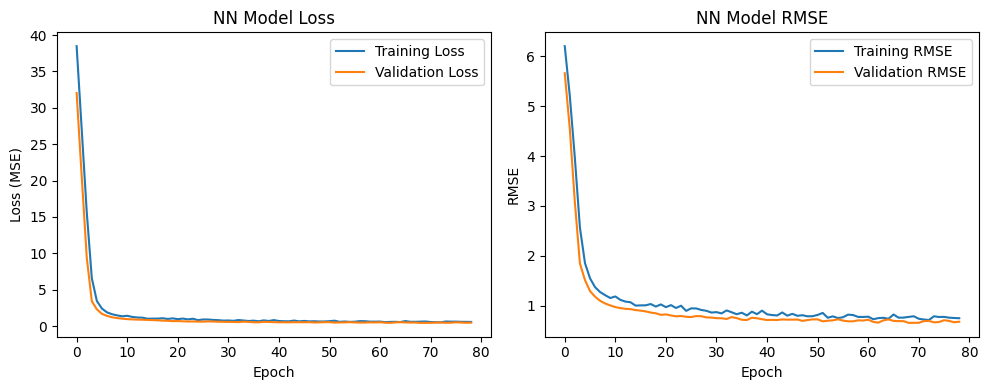

--------------------------------------------------


In [ ]:
# Block 8: Model Training - Neural Network (MLP) - Training
print("Block 8: Training Neural Network (MLP)...")

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)

# Train the model
# validation_split uses the last 12.5% of X_train_processed_nn for validation (10% of original total data if train is 80%)
history = nn_model.fit(
    X_train_processed_nn, y_train,
    epochs=100, # Max epochs
    batch_size=32,
    validation_split=0.125, # (0.1 total data) / (0.8 training data) = 0.125 of training for validation
    callbacks=[early_stopping],
    verbose=1
)
models['Neural Network'] = nn_model
print("Neural Network training complete.")

# Plot training history (optional but good practice)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('NN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['rmse'], label='Training RMSE')
plt.plot(history.history['val_rmse'], label='Validation RMSE')
plt.title('NN Model RMSE')
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.legend()
plt.tight_layout()
plt.show()
print("-" * 50)
# --- End of Block 8 ---

## Model Evaluation

In [ ]:
# Block 9: Model Evaluation - Overall Performance
print("Block 9: Evaluating models on the Test Set...")
# --- Model Evaluation (on Test Set) ---
for name, model_obj in models.items():
    print(f"\nEvaluating: {name}")
    if name == 'Neural Network':
        # NN requires preprocessed data (X_test_processed_nn)
        y_pred = model_obj.predict(X_test_processed_nn).flatten()
    else:
        # Scikit-learn pipelines handle preprocessing internally
        y_pred = model_obj.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results[name] = {'RMSE': rmse, 'MAE': mae, 'R2': r2}
    print(f"  RMSE: {rmse:.4f} tonnes/ha")
    print(f"  MAE:  {mae:.4f} tonnes/ha")
    print(f"  R²:   {r2:.4f}")

results_df = pd.DataFrame(results).T.sort_values(by="RMSE") # Sort by RMSE
print("\n--- Overall Model Performance Summary (Sorted by RMSE) ---")
print(results_df)
print("-" * 50)
# --- End of Block 9 ---

Block 9: Evaluating models on the Test Set...

Evaluating: Linear Regression
  RMSE: 0.5708 tonnes/ha
  MAE:  0.4270 tonnes/ha
  R²:   0.7555

Evaluating: Random Forest
  RMSE: 0.5075 tonnes/ha
  MAE:  0.3751 tonnes/ha
  R²:   0.8067

Evaluating: Neural Network
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
  RMSE: 0.5636 tonnes/ha
  MAE:  0.4221 tonnes/ha
  R²:   0.7616

--- Overall Model Performance Summary (Sorted by RMSE) ---
                       RMSE       MAE        R2
Random Forest      0.507541  0.375090  0.806684
Neural Network     0.563580  0.422126  0.761638
Linear Regression  0.570785  0.427026  0.755505
--------------------------------------------------


## Regional-crop Specific Evaluation and Visualisation- RANDOM FOREST

Block 10: Performing Regional/Crop-Specific Evaluation and Visualization...
Performing detailed evaluation for the 'best' model: Random Forest

--- Regional and Crop-Specific Performance (Best Model) ---
                       Region    Crop      RMSE       MAE        R2  N_Samples
23              East Midlands  barley  0.321675  0.289584 -0.472653          5
21              East Midlands    oats  0.524721  0.348064  0.221997          5
22              East Midlands   wheat  0.487916  0.437900  0.351161          5
11                    Eastern  barley  0.261308  0.230928  0.098424          5
9                     Eastern    oats  0.396294  0.349640  0.305265          5
10                    Eastern   wheat  0.447745  0.365944  0.448213          5
17                 North East  barley  0.232543  0.195436  0.641462          5
15                 North East    oats  0.600768  0.525068  0.359822          5
16                 North East   wheat  0.431566  0.387232  0.580119          5
20  No

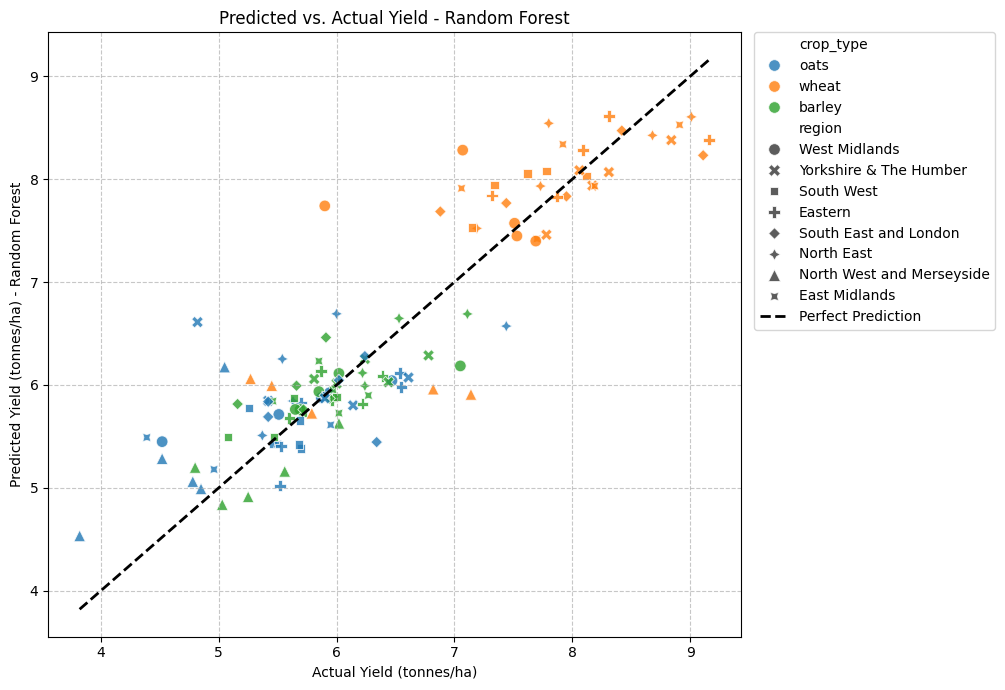

--------------------------------------------------


In [ ]:
# Block 10: Regional/Crop-Specific Evaluation and Visualization
print("Block 10: Performing Regional/Crop-Specific Evaluation and Visualization...")
# --- Regional and Crop-Specific Evaluation ---
# Use the best model based on overall RMSE
best_model_name = results_df.index[0] # Assumes results_df is sorted by RMSE ascending
best_model = models[best_model_name]

print(f"Performing detailed evaluation for the 'best' model: {best_model_name}")

# Create a copy of X_test to add actual and predicted values for analysis
# X_test still has original categorical features before one-hot encoding.
X_test_analysis = X_test.copy()
X_test_analysis['yield_actual'] = y_test

if best_model_name == 'Neural Network':
    X_test_analysis['yield_predicted'] = best_model.predict(X_test_processed_nn).flatten()
else:
    X_test_analysis['yield_predicted'] = best_model.predict(X_test) # X_test for scikit-learn pipelines

regional_crop_results = []
for region in X_test_analysis['region'].unique():
    for crop in X_test_analysis['crop_type'].unique():
        subset = X_test_analysis[
            (X_test_analysis['region'] == region) &
            (X_test_analysis['crop_type'] == crop)
        ]
        if not subset.empty:
            y_true_subset = subset['yield_actual']
            y_pred_subset = subset['yield_predicted']

            # Ensure there are enough samples to calculate metrics reliably
            if len(y_true_subset) > 1: # R2 needs at least 2 samples
                rmse_s = np.sqrt(mean_squared_error(y_true_subset, y_pred_subset))
                mae_s = mean_absolute_error(y_true_subset, y_pred_subset)
                r2_s = r2_score(y_true_subset, y_pred_subset)
            elif len(y_true_subset) == 1: # Can calculate RMSE/MAE, R2 is undefined or 0
                rmse_s = np.sqrt(mean_squared_error(y_true_subset, y_pred_subset))
                mae_s = mean_absolute_error(y_true_subset, y_pred_subset)
                r2_s = np.nan # Or 0, depending on preference for single-sample cases
            else: # Should not happen if subset is not empty, but good to be safe
                rmse_s, mae_s, r2_s = np.nan, np.nan, np.nan

            regional_crop_results.append({
                'Region': region, 'Crop': crop,
                'RMSE': rmse_s, 'MAE': mae_s, 'R2': r2_s, 'N_Samples': len(subset)
            })

regional_crop_df = pd.DataFrame(regional_crop_results)
print("\n--- Regional and Crop-Specific Performance (Best Model) ---")
print(regional_crop_df.sort_values(by=['Region', 'Crop']))

# --- Visualizations (Predicted vs. Actual for best model) ---
plt.figure(figsize=(12, 7))
sns.scatterplot(x='yield_actual', y='yield_predicted', data=X_test_analysis,
                hue='crop_type', style='region', alpha=0.8, s=70)
min_val = min(X_test_analysis['yield_actual'].min(), X_test_analysis['yield_predicted'].min())
max_val = max(X_test_analysis['yield_actual'].max(), X_test_analysis['yield_predicted'].max())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2, label="Perfect Prediction") # Diagonal line
plt.xlabel("Actual Yield (tonnes/ha)")
plt.ylabel(f"Predicted Yield (tonnes/ha) - {best_model_name}")
plt.title(f"Predicted vs. Actual Yield - {best_model_name}")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout(rect=[0, 0, 0.85, 1]) # Adjust layout to make space for legend
plt.show()
print("-" * 50)
# --- End of Block 10 ---

## Individual Performance Analysis by Region and Crop Type

Block 10a: Analyzing Performance by Region and Crop Type Separately...
Using best model: Random Forest

--- Performance Analysis by Region (Random Forest) ---
                      Region      RMSE       MAE        R2  N_Samples
0                 South West  0.313183  0.251253  0.901663         15
1                    Eastern  0.376743  0.315504  0.887415         15
2                 North East  0.447678  0.369245  0.832645         15
3              East Midlands  0.453457  0.358516  0.864950         15
4      South East and London  0.479180  0.365272  0.828267         15
5     Yorkshire & The Humber  0.559545  0.372261  0.765252         15
6  North West and Merseyside  0.645987  0.548933  0.384935         15
7              West Midlands  0.674330  0.419732  0.403377         15


<ipython-input-47-f736b88dc4ec>:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=regional_metrics_df, y='Region', x='RMSE', palette='coolwarm', order=regional_metrics_df['Region']) # Use sorted order


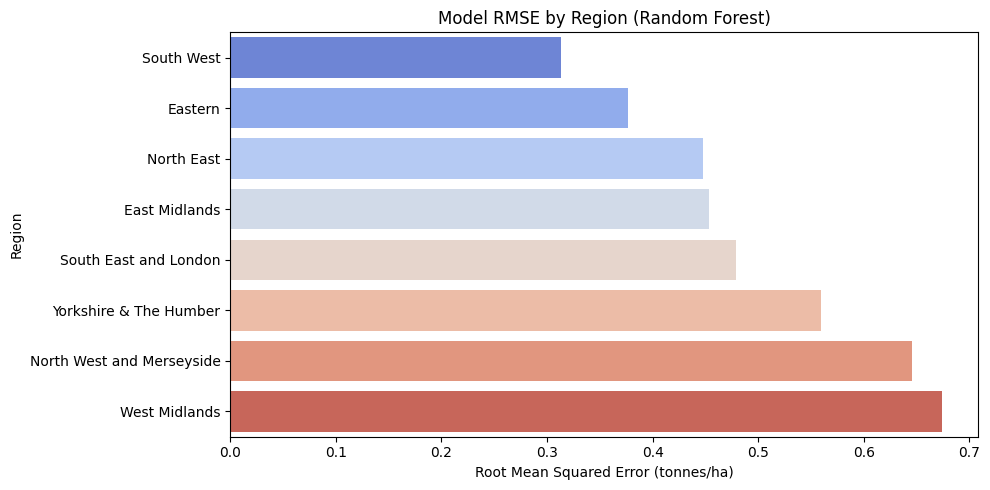


--- Performance Analysis by Crop Type (Random Forest) ---
     Crop      RMSE       MAE        R2  N_Samples
0  barley  0.320209  0.254087  0.574961         40
1    oats  0.565351  0.416145  0.323744         40
2   wheat  0.592146  0.455037  0.577686         40


<ipython-input-47-f736b88dc4ec>:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=crop_metrics_df, y='Crop', x='RMSE', palette='viridis', order=crop_metrics_df['Crop']) # Use sorted order


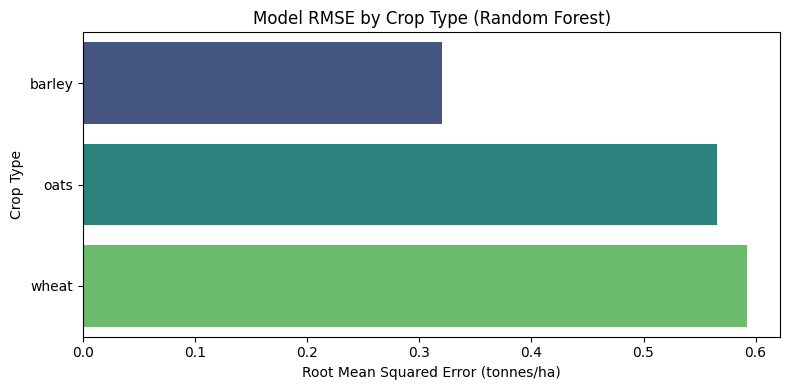

--------------------------------------------------


In [ ]:
# Block 10a: Performance Analysis by Region and Crop Type (Separately)
print("Block 10a: Analyzing Performance by Region and Crop Type Separately...")

# Ensure X_test_analysis and best_model_name from Block 10 are available
if 'X_test_analysis' not in locals() or 'best_model_name' not in locals():
    print("Error: Required variables ('X_test_analysis', 'best_model_name') not found.")
    print("Please ensure Block 10 has been executed successfully before running Block 10a.")
    # Optionally raise an error or exit
    # raise RuntimeError("Prerequisite blocks not executed.")
else:
    print(f"Using best model: {best_model_name}")

    # --- Performance by Region ---
    print(f"\n--- Performance Analysis by Region ({best_model_name}) ---")
    regional_metrics = []
    # Group by region and calculate metrics for each
    for region in sorted(X_test_analysis['region'].unique()): # Sort for consistent order
        subset = X_test_analysis[X_test_analysis['region'] == region]
        y_true_r = subset['yield_actual']
        y_pred_r = subset['yield_predicted']
        n_samples_r = len(subset)

        if n_samples_r > 1:
            rmse_r = np.sqrt(mean_squared_error(y_true_r, y_pred_r))
            mae_r = mean_absolute_error(y_true_r, y_pred_r)
            r2_r = r2_score(y_true_r, y_pred_r)
        elif n_samples_r == 1: # Handle single sample cases for RMSE/MAE, R2 is undefined
            rmse_r = np.sqrt(mean_squared_error(y_true_r, y_pred_r))
            mae_r = mean_absolute_error(y_true_r, y_pred_r)
            r2_r = np.nan
        else: # Should not happen if region exists, but safe practice
            rmse_r, mae_r, r2_r = np.nan, np.nan, np.nan

        regional_metrics.append({
            'Region': region,
            'RMSE': rmse_r,
            'MAE': mae_r,
            'R2': r2_r,
            'N_Samples': n_samples_r
        })

    regional_metrics_df = pd.DataFrame(regional_metrics).sort_values(by='RMSE').reset_index(drop=True)
    print(regional_metrics_df)

    # Visualize Regional Performance (RMSE)
    plt.figure(figsize=(10, max(5, len(regional_metrics_df) * 0.6))) # Adjust height based on number of regions
    sns.barplot(data=regional_metrics_df, y='Region', x='RMSE', palette='coolwarm', order=regional_metrics_df['Region']) # Use sorted order
    plt.title(f'Model RMSE by Region ({best_model_name})')
    plt.xlabel('Root Mean Squared Error (tonnes/ha)')
    plt.ylabel('Region')
    plt.tight_layout()
    plt.show()

    # --- Performance by Crop Type ---
    print(f"\n--- Performance Analysis by Crop Type ({best_model_name}) ---")
    crop_metrics = []
    # Group by crop type and calculate metrics for each
    for crop in sorted(X_test_analysis['crop_type'].unique()): # Sort for consistent order
        subset = X_test_analysis[X_test_analysis['crop_type'] == crop]
        y_true_c = subset['yield_actual']
        y_pred_c = subset['yield_predicted']
        n_samples_c = len(subset)

        if n_samples_c > 1:
             rmse_c = np.sqrt(mean_squared_error(y_true_c, y_pred_c))
             mae_c = mean_absolute_error(y_true_c, y_pred_c)
             r2_c = r2_score(y_true_c, y_pred_c)
        elif n_samples_c == 1:
             rmse_c = np.sqrt(mean_squared_error(y_true_c, y_pred_c))
             mae_c = mean_absolute_error(y_true_c, y_pred_c)
             r2_c = np.nan
        else:
             rmse_c, mae_c, r2_c = np.nan, np.nan, np.nan

        crop_metrics.append({
            'Crop': crop,
            'RMSE': rmse_c,
            'MAE': mae_c,
            'R2': r2_c,
            'N_Samples': n_samples_c
        })

    crop_metrics_df = pd.DataFrame(crop_metrics).sort_values(by='RMSE').reset_index(drop=True)
    print(crop_metrics_df)

    # Visualize Crop Performance (RMSE)
    plt.figure(figsize=(8, max(4, len(crop_metrics_df) * 0.8))) # Adjust height based on number of crops
    sns.barplot(data=crop_metrics_df, y='Crop', x='RMSE', palette='viridis', order=crop_metrics_df['Crop']) # Use sorted order
    plt.title(f'Model RMSE by Crop Type ({best_model_name})')
    plt.xlabel('Root Mean Squared Error (tonnes/ha)')
    plt.ylabel('Crop Type')
    plt.tight_layout()
    plt.show()

print("-" * 50)
# --- End of Block 10a ---

## Feature Importance Plot

Block 11: Displaying Random Forest Feature Importances (if applicable)...

--- Random Forest Feature Importances ---
Top 15 Feature Importances:
                                     feature  importance
0                    onehot__crop_type_wheat    0.478586
1                    scaler__prev_year_yield    0.154451
2   onehot__region_North West and Merseyside    0.110387
3                               scaler__year    0.072604
4                                scaler__sun    0.029136
5           scaler__tas_rainfall_interaction    0.027266
6                           scaler__rainfall    0.025855
7                             scaler__tasmin    0.024811
8                             scaler__tasmax    0.023016
9                                scaler__tas    0.016519
10                 onehot__region_South West    0.009422
11                  onehot__crop_type_barley    0.006575
12              onehot__region_West Midlands    0.006449
13                    onehot__crop_type_oats    0.006332


<ipython-input-48-53f630623dc2>:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=feature_importance_df.head(15), palette="viridis")


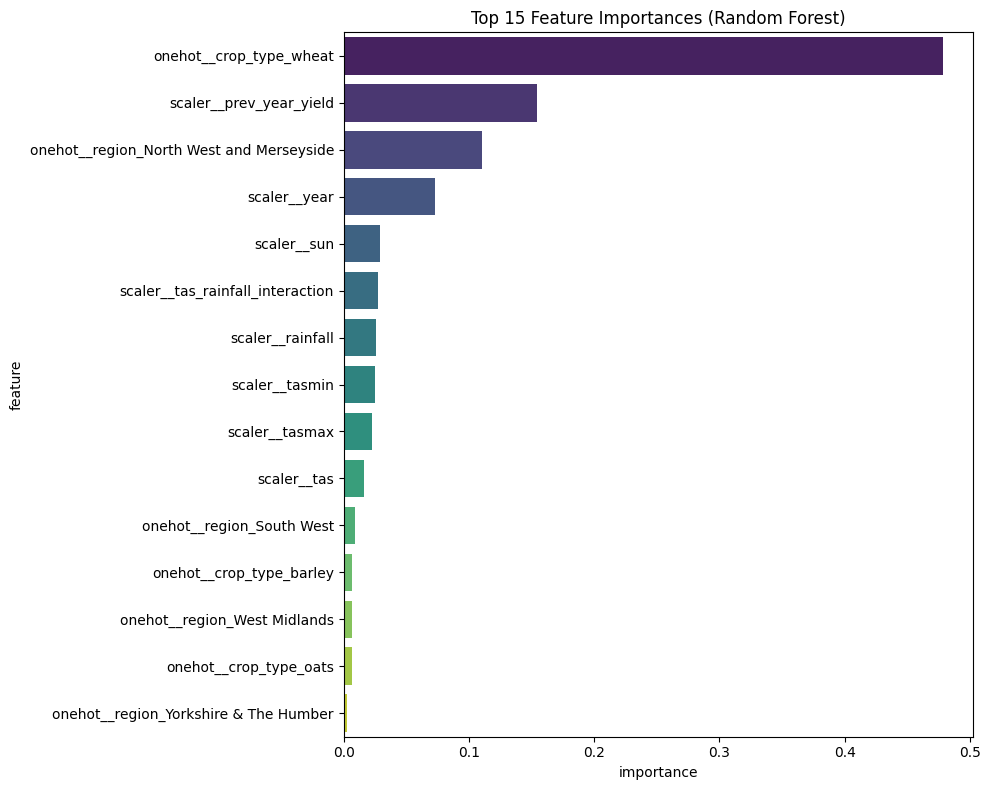

--------------------------------------------------


In [ ]:
# Block 11: Feature Importances (for Random Forest)
print("Block 11: Displaying Random Forest Feature Importances (if applicable)...")
# --- Random Forest Feature Importance (if RF is one of the models) ---
if 'Random Forest' in models:
    print("\n--- Random Forest Feature Importances ---")
    rf_model_from_pipeline = models['Random Forest'].named_steps['regressor']

    # Get feature names after one-hot encoding from the preprocessor step in the pipeline
    # The preprocessor used for RF was part of rf_pipeline, which is rf_grid_search.best_estimator_
    rf_preprocessor = models['Random Forest'].named_steps['preprocessor']

    try:
        # For scikit-learn >= 0.24 or 1.0+
        feature_names_out = rf_preprocessor.get_feature_names_out()
    except AttributeError:
        # Fallback for older versions or if get_feature_names_out is not directly available on the ColumnTransformer
        # This part can be tricky depending on the exact scikit-learn version and how transformers are named.
        # Let's try to get it from the one-hot encoder part and numerical features directly.
        ohe_transformer = rf_preprocessor.named_transformers_['onehot']
        ohe_feature_names = ohe_transformer.get_feature_names_out(categorical_features)

        # Numerical features names remain the same after StandardScaler
        # We need to ensure numerical_features list matches the one used in the preprocessor
        num_feature_names = numerical_features # This was defined globally earlier

        feature_names_out = np.concatenate([ohe_feature_names, num_feature_names])

    importances = rf_model_from_pipeline.feature_importances_
    feature_importance_df = pd.DataFrame({'feature': feature_names_out, 'importance': importances})
    feature_importance_df = feature_importance_df.sort_values('importance', ascending=False).reset_index(drop=True)

    print("Top 15 Feature Importances:")
    print(feature_importance_df.head(15))

    plt.figure(figsize=(10, 8))
    sns.barplot(x='importance', y='feature', data=feature_importance_df.head(15), palette="viridis")
    plt.title("Top 15 Feature Importances (Random Forest)")
    plt.tight_layout()
    plt.show()
else:
    print("Random Forest model not in the list of trained models. Skipping feature importances.")
print("-" * 50)
# --- End of Block 11 ---

## Saving the models = Random Forest and Linear Regression

In [ ]:
# In your training script (e.g., Block 5 and 6 led to these)
# lr_pipeline = Pipeline(steps=[('preprocessor', preprocessor_instance_for_lr), ('regressor', LinearRegression())])
# rf_grid_search.best_estimator_ # This IS the pipeline for RF

models['Linear Regression'] = lr_pipeline # This IS a pipeline
models['Random Forest'] = rf_grid_search.best_estimator_ # This IS a pipeline

# Then when saving:
joblib.dump(models['Linear Regression'], "linear_regression_model.joblib")
joblib.dump(models['Random Forest'], "random_forest_model.joblib")

['random_forest_model.joblib']

In [ ]:
# # In your training script (Block 12)
# import os
# # preprocessor was your ColumnTransformer instance
# preprocessor_path = os.path.join(DRIVE_MODEL_DIR, "preprocessor.joblib")
# joblib.dump(preprocessor, preprocessor_path)

# Model Deployment

## Set up and Mount Google Drive

In [ ]:
# Step 1: Setup and Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Create a directory in your Drive to store models if it doesn't exist
# (run this cell once per session if needed)
import os
DRIVE_MODEL_DIR = '/content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models' # Adjust path as needed
os.makedirs(DRIVE_MODEL_DIR, exist_ok=True)
print(f"Model directory set to: {DRIVE_MODEL_DIR}")

# Install necessary libraries
!pip install streamlit -q
!pip install pyngrok -q # For exposing the Streamlit app
!pip install joblib scikit-learn pandas numpy tensorflow matplotlib seaborn

print("Setup complete.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model directory set to: /content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models
Setup complete.


## Adapt Training code to saved models

In [ ]:
# Step 2: Training Code (Condensed Example - you'd paste your full Blocks 1-11 here)
# ... (Your full training code from Block 1 to Block 11) ...
# Make sure your DATA_FILE = "UK_crop_climate_data.xlsx" is uploaded to Colab's root
# or you adjust the path if it's in Drive.



# (Assuming 'models', 'preprocessor', 'categorical_features', 'numerical_features'
# are defined from your training script)

import joblib
import pickle
from tensorflow import keras # Ensure keras is imported if saving NN model

print("Saving trained models, preprocessor, and feature info to Google Drive...")

# Save models
for name, model_obj in models.items(): # 'models' is the dictionary from your training script
    if name == 'Neural Network':
        model_path = os.path.join(DRIVE_MODEL_DIR, f"{name.lower().replace(' ', '_')}_model.keras")
        model_obj.save(model_path)
        print(f"Saved {name} to {model_path}")
    else:
        model_path = os.path.join(DRIVE_MODEL_DIR, f"{name.lower().replace(' ', '_')}_model.joblib")
        joblib.dump(model_obj, model_path)
        print(f"Saved {name} to {model_path}")

# Save the fitted preprocessor
preprocessor_path = os.path.join(DRIVE_MODEL_DIR, "preprocessor.joblib")
joblib.dump(preprocessor, preprocessor_path) # 'preprocessor' is the ColumnTransformer instance
print(f"Saved preprocessor to {preprocessor_path}")

# Save feature names
feature_info = {
    'categorical_features': categorical_features, # from your training script's Block 4
    'numerical_features': numerical_features     # from your training script's Block 4
}
feature_info_path = os.path.join(DRIVE_MODEL_DIR, "feature_info.pkl")
with open(feature_info_path, 'wb') as f:
    pickle.dump(feature_info, f)
print(f"Saved feature info to {feature_info_path}")

print("Models, preprocessor, and feature info saved to Google Drive.")
print("-" * 50)

# --- End of Training Code Adaptation ---

Saving trained models, preprocessor, and feature info to Google Drive...
Saved Linear Regression to /content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models/linear_regression_model.joblib
Saved Random Forest to /content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models/random_forest_model.joblib
Saved Neural Network to /content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models/neural_network_model.keras
Saved preprocessor to /content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models/preprocessor.joblib
Saved feature info to /content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models/feature_info.pkl
Models, preprocessor, and feature info saved to Google Drive.
--------------------------------------------------


In [ ]:
# # Step 3: Write the Streamlit App Code to a file (app.py) - ADAPTED FOR MODEL TYPE

# %%writefile app.py
# # app.py - Streamlit UI for Crop Yield Prediction (Colab Version)

# import streamlit as st
# import pandas as pd
# import numpy as np
# import joblib
# import pickle
# from tensorflow import keras # For loading Keras model
# import os

# # --- Configuration ---
# MODEL_DIR = '/content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models' # MUST MATCH DRIVE_MODEL_DIR from Step 1
# DEFAULT_MODEL_NAME = "Random Forest"

# # --- Helper Functions ---
# @st.cache_resource
# def load_model_and_dependencies(model_name_to_load):
#     feature_info_path = os.path.join(MODEL_DIR, "feature_info.pkl")
#     loaded_preprocessor_obj = None # Initialize for separate loading

#     if not os.path.exists(feature_info_path):
#         st.error(f"Feature info file not found at {feature_info_path}.")
#         return None, None, None, None
#     with open(feature_info_path, 'rb') as f:
#         feature_info = pickle.load(f)

#     loaded_categorical_features = feature_info['categorical_features']
#     loaded_numerical_features = feature_info['numerical_features']

#     # Load the SEPARATE preprocessor only if needed (e.g., for Neural Network)
#     # Scikit-learn pipelines will have their own internal preprocessor.
#     preprocessor_path = os.path.join(MODEL_DIR, "preprocessor.joblib")
#     if os.path.exists(preprocessor_path):
#         loaded_preprocessor_obj = joblib.load(preprocessor_path)
#     else:
#         # This is critical only if we have a model type that needs separate preprocessing
#         if model_name_to_load == "Neural Network": # Example: NN needs it
#              st.error(f"Separate preprocessor file not found at {preprocessor_path}, but needed for Neural Network.")
#              return None, None, None, None


#     # Load model
#     model_filename_stub = model_name_to_load.lower().replace(' ', '_')
#     loaded_model_obj = None
#     if model_name_to_load == "Neural Network":
#         model_path = os.path.join(MODEL_DIR, f"{model_filename_stub}_model.keras")
#         if not os.path.exists(model_path):
#             st.error(f"Model file for {model_name_to_load} not found at {model_path}.")
#             return None, None, None, None
#         loaded_model_obj = keras.models.load_model(model_path)
#     else: # For scikit-learn pipeline models (Linear Regression, Random Forest)
#         model_path = os.path.join(MODEL_DIR, f"{model_filename_stub}_model.joblib")
#         if not os.path.exists(model_path):
#             st.error(f"Model file for {model_name_to_load} not found at {model_path}.")
#             return None, None, None, None
#         loaded_model_obj = joblib.load(model_path)

#     return loaded_model_obj, loaded_preprocessor_obj, loaded_categorical_features, loaded_numerical_features

# # --- UI Layout ---
# st.set_page_config(page_title="UK Crop Yield Predictor", layout="wide")
# st.title("🌾 UK Crop Yield Prediction (Colab)")
# # ... (rest of UI intro markdown) ...

# st.sidebar.header("Input Parameters for Prediction")
# # ... (model selection code using `ui_selected_model_name`) ...
# # Load the selected model and its dependencies
# # `preprocessor_for_nn` is the separately saved preprocessor, might be None if not found or not needed by the current model
# model, preprocessor_for_nn, categorical_features, numerical_features = load_model_and_dependencies(ui_selected_model_name)


# if not model or not categorical_features or not numerical_features:
#     st.warning("Model or feature lists could not be loaded. Check logs and file paths.")
#     st.stop()
# # If it's a NN and preprocessor_for_nn is None, it would have stopped in load_model_and_dependencies

# # ... (UI input fields: ui_region, ui_crop_type, ui_year, etc. as before) ...
# # Ensure all UI inputs are collected correctly.

# if st.sidebar.button("Predict Crop Yield"):
#     # Construct the input DataFrame with the ORIGINAL 10 features
#     data_for_df = {}
#     if 'region' in categorical_features: data_for_df['region'] = [ui_region]
#     if 'crop_type' in categorical_features: data_for_df['crop_type'] = [ui_crop_type]
#     if 'year' in numerical_features: data_for_df['year'] = [ui_year]
#     if 'tas' in numerical_features: data_for_df['tas'] = [ui_tas]
#     if 'tasmin' in numerical_features: data_for_df['tasmin'] = [ui_tasmin]
#     if 'tasmax' in numerical_features: data_for_df['tasmax'] = [ui_tasmax]
#     if 'sun' in numerical_features: data_for_df['sun'] = [ui_sun]
#     if 'rainfall' in numerical_features: data_for_df['rainfall'] = [ui_rainfall]

#     # Calculate engineered feature `tas_rainfall_interaction`
#     current_tas_rainfall_interaction = ui_tas * ui_rainfall

#     if 'tas_rainfall_interaction' in numerical_features:
#         data_for_df['tas_rainfall_interaction'] = [current_tas_rainfall_interaction]
#     if 'prev_year_yield' in numerical_features:
#         if ui_prev_year_yield is not None:
#             data_for_df['prev_year_yield'] = [ui_prev_year_yield]
#         else:
#             st.error("'prev_year_yield' expected but not provided from UI.")
#             st.stop()

#     expected_original_features = categorical_features + numerical_features

#     try:
#         # This DataFrame has the original 10 features
#         df_original_features = pd.DataFrame(data_for_df)
#         df_original_features = df_original_features[expected_original_features] # Ensure order and selection
#     except KeyError as e:
#         st.error(f"Error creating initial DataFrame. Missing key: {e}.")
#         st.stop()

#     # st.write("DataFrame with original features (before any preprocessing in app):")
#     # st.dataframe(df_original_features)
#     # st.write(f"Shape: {df_original_features.shape}")

#     input_for_model = None # This will hold the data in the format the specific model needs

#     try:
#         if ui_selected_model_name == "Neural Network":
#             if preprocessor_for_nn is None:
#                 st.error("Neural Network selected, but the separate preprocessor was not loaded. Cannot proceed.")
#                 st.stop()
#             # Neural Network expects data to be preprocessed by the *separate* preprocessor
#             input_for_model = preprocessor_for_nn.transform(df_original_features)
#             # st.write(f"Data shape after separate preprocessing for NN: {input_for_model.shape}") # Should be (1, 19)

#         elif ui_selected_model_name in ["Random Forest", "Linear Regression"]:
#             # Scikit-learn pipelines (Random Forest, Linear Regression) do their own preprocessing.
#             # Pass the DataFrame with original features directly.
#             input_for_model = df_original_features
#             # st.write(f"Data shape for SKLearn Pipeline model: {input_for_model.shape}") # Should be (1, 10)

#         else:
#             st.error(f"Model type '{ui_selected_model_name}' not recognized for specific preprocessing path.")
#             st.stop()

#         # Now, make the prediction
#         prediction = model.predict(input_for_model)
#         predicted_yield = prediction[0] if isinstance(prediction[0], (int, float, np.float32, np.float64)) else prediction[0][0]

#         st.subheader("Prediction Result:")
#         st.metric(label=f"Predicted Yield for {ui_crop_type.capitalize()} in {ui_region}",
#                   value=f"{predicted_yield:.2f} tonnes/ha")
#         # ... (info display as before) ...

#     except ValueError as ve:
#         st.error(f"ValueError during prediction or preprocessing: {ve}")
#         # import traceback
#         # st.text(traceback.format_exc()) # For more detailed error
#     except Exception as e:
#         st.error(f"An unexpected error: {e}")
#         # import traceback
#         # st.text(traceback.format_exc())

# else:
#     st.info("Adjust parameters and click 'Predict Crop Yield'.")

# st.markdown("---")
# # ... (footer markdown) ...

## Develop UI

In [ ]:
%%writefile app.py
# app.py - Streamlit UI for Crop Yield Prediction (Colab Version)

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import pickle
from tensorflow import keras # For loading Keras model
import os

# --- Configuration ---
MODEL_DIR = '/content/drive/MyDrive/ColabNotebooks/UK_Crop_Yield/trained_models' # MUST MATCH DRIVE_MODEL_DIR from Step 1
DEFAULT_MODEL_NAME = "Random Forest" # Ensure this is one of your model names

# --- Helper Functions ---
@st.cache_resource # Use st.cache_resource for models and non-data objects
def load_model_and_dependencies(model_name_to_load):
    feature_info_path = os.path.join(MODEL_DIR, "feature_info.pkl")
    loaded_preprocessor_obj = None

    if not os.path.exists(feature_info_path):
        st.error(f"Feature info file not found at {feature_info_path}. Ensure training and saving ran successfully.")
        return None, None, None, None
    with open(feature_info_path, 'rb') as f:
        feature_info = pickle.load(f)

    loaded_categorical_features = feature_info['categorical_features']
    loaded_numerical_features = feature_info['numerical_features']

    preprocessor_path = os.path.join(MODEL_DIR, "preprocessor.joblib")
    if os.path.exists(preprocessor_path):
        loaded_preprocessor_obj = joblib.load(preprocessor_path)
    else:
        if model_name_to_load == "Neural Network":
             st.error(f"Separate preprocessor file not found at {preprocessor_path}, but needed for Neural Network.")
             return None, None, None, None # Critical for NN

    model_filename_stub = model_name_to_load.lower().replace(' ', '_')
    loaded_model_obj = None
    if model_name_to_load == "Neural Network":
        model_path = os.path.join(MODEL_DIR, f"{model_filename_stub}_model.keras")
        if not os.path.exists(model_path):
            st.error(f"Model file for {model_name_to_load} not found at {model_path}.")
            return None, None, None, None
        loaded_model_obj = keras.models.load_model(model_path)
    else: # For scikit-learn pipeline models
        model_path = os.path.join(MODEL_DIR, f"{model_filename_stub}_model.joblib")
        if not os.path.exists(model_path):
            st.error(f"Model file for {model_name_to_load} not found at {model_path}.")
            return None, None, None, None
        loaded_model_obj = joblib.load(model_path)

    st.success(f"Successfully loaded model: {model_name_to_load} and its dependencies.")
    return loaded_model_obj, loaded_preprocessor_obj, loaded_categorical_features, loaded_numerical_features

# --- UI Layout ---
st.set_page_config(page_title="UK Crop Yield Predictor", layout="wide")
st.title("🌾 UK Crop Yield Prediction (Colab)")
st.markdown("""
Welcome to the UK Crop Yield Predictor!
This tool uses machine learning models to forecast crop yields based on various factors.
Please select a model and input the required parameters in the sidebar.
""")

st.sidebar.header("Model & Input Parameters")

# ***** FIX STARTS HERE *****
# Model selection
# Define available model names - these MUST match how they were saved (e.g., "Random Forest", "Neural Network")
# You can also make this dynamic by listing files in MODEL_DIR if you prefer
available_model_names = ["Random Forest", "Linear Regression", "Neural Network"] # Adjust if your model names are different

# Ensure DEFAULT_MODEL_NAME is valid or pick the first one
if DEFAULT_MODEL_NAME not in available_model_names and available_model_names:
    current_default_model_name = available_model_names[0]
elif not available_model_names:
    st.error("No models available for selection. Please check your saved models.")
    st.stop() # Stop if no models are defined
else:
    current_default_model_name = DEFAULT_MODEL_NAME

ui_selected_model_name = st.sidebar.selectbox(
    "Select Prediction Model:",
    options=available_model_names,
    index=available_model_names.index(current_default_model_name) # Set default selection
)
# ***** FIX ENDS HERE *****


# Load the selected model and its dependencies
model, preprocessor_for_nn, categorical_features, numerical_features = load_model_and_dependencies(ui_selected_model_name)

if not model or not categorical_features or not numerical_features:
    st.warning("Model, preprocessor, or feature lists could not be loaded. Please check the Google Drive paths and ensure the training script (Step 2) has been run successfully to save all necessary files. Check error messages above for details.")
    st.stop()

# UI input fields:
# These should align with your `categorical_features` and `numerical_features`
# (Excluding 'year' if it's not a direct model input or handled differently)
# Make sure these lists are correct based on what your preprocessor expects from the original dataframe
st.sidebar.subheader("Input Features:")

# Example: Get unique values from your training data for dropdowns if available,
# otherwise, provide sensible defaults or lists.
# For simplicity, using predefined lists here.
# Ensure these are consistent with your training data's unique values.

# Categorical Inputs
if 'region' in categorical_features:

    regions = ['East Midlands', 'Eastern', 'North East', 'North West', 'South East', 'South West', 'West Midlands', 'Yorkshire and the Humber'] # Example regions
    ui_region = st.sidebar.selectbox("Region", options=regions, index=0)

if 'crop_type' in categorical_features:

    crop_types = ['wheat', 'barley', 'oats'] # Example crop types
    ui_crop_type = st.sidebar.selectbox("Crop Type", options=crop_types, index=0)

# Numerical Inputs
if 'year' in numerical_features: # Assuming year is a numerical input
    ui_year = st.sidebar.number_input("Year", min_value=2000, max_value=2050, value=2023, step=1)

if 'tas' in numerical_features:
    ui_tas = st.sidebar.slider("Average Temperature (°C) - tas", -5.0, 25.0, 10.0, 0.1)
if 'tasmin' in numerical_features:
    ui_tasmin = st.sidebar.slider("Min Temperature (°C) - tasmin", -10.0, 20.0, 5.0, 0.1)
if 'tasmax' in numerical_features:
    ui_tasmax = st.sidebar.slider("Max Temperature (°C) - tasmax", 0.0, 35.0, 15.0, 0.1)
if 'sun' in numerical_features:
    ui_sun = st.sidebar.slider("Sunshine Hours - sun", 0.0, 2000.0, 150.0, 1.0)
if 'rainfall' in numerical_features:
    ui_rainfall = st.sidebar.slider("Rainfall (mm) - rainfall", 0.0, 2000.0, 70.0, 1.0)

# This one is special as it might not be in numerical_features if it's directly used for prev_year_yield
# Or, it might be imputed/handled if not available. For now, assuming it's required.
# It's important how 'prev_year_yield' was handled during training.
# If 'prev_year_yield' is NOT in your `numerical_features` list saved by training,
# then this input should NOT be created, or the logic below needs to adapt.
ui_prev_year_yield = None # Initialize
if 'prev_year_yield' in numerical_features:
    ui_prev_year_yield = st.sidebar.number_input("Previous Year's Yield (tonnes/ha)", min_value=0.0, value=7.5, step=0.1)
elif any('prev_year_yield' in col for col in (numerical_features + categorical_features)): # Check if it's part of any feature name
    st.sidebar.warning("`prev_year_yield` seems to be part of features but not directly in numerical_features. Consider how it's handled.")


if st.sidebar.button("Predict Crop Yield"):
    # Construct the input DataFrame with the ORIGINAL features
    data_for_df = {}
    # Use the loaded categorical_features and numerical_features to build the dict
    # This ensures we only try to add features the model was trained on.

    if 'region' in categorical_features: data_for_df['region'] = [ui_region]
    if 'crop_type' in categorical_features: data_for_df['crop_type'] = [ui_crop_type]

    # For numerical features, check if the UI element was created
    if 'year' in numerical_features and 'ui_year' in locals(): data_for_df['year'] = [ui_year]
    if 'tas' in numerical_features and 'ui_tas' in locals(): data_for_df['tas'] = [ui_tas]
    if 'tasmin' in numerical_features and 'ui_tasmin' in locals(): data_for_df['tasmin'] = [ui_tasmin]
    if 'tasmax' in numerical_features and 'ui_tasmax' in locals(): data_for_df['tasmax'] = [ui_tasmax]
    if 'sun' in numerical_features and 'ui_sun' in locals(): data_for_df['sun'] = [ui_sun]
    if 'rainfall' in numerical_features and 'ui_rainfall' in locals(): data_for_df['rainfall'] = [ui_rainfall]

    # Engineered feature: tas_rainfall_interaction
    # This MUST be created if it was part of numerical_features during training
    if 'tas_rainfall_interaction' in numerical_features:
        if 'ui_tas' in locals() and 'ui_rainfall' in locals():
            current_tas_rainfall_interaction = ui_tas * ui_rainfall
            data_for_df['tas_rainfall_interaction'] = [current_tas_rainfall_interaction]
        else:
            st.error("Cannot calculate 'tas_rainfall_interaction' as 'tas' or 'rainfall' input is missing.")
            st.stop()

    if 'prev_year_yield' in numerical_features:
        if ui_prev_year_yield is not None:
            data_for_df['prev_year_yield'] = [ui_prev_year_yield]
        else:
            # This case should be handled by the UI input creation logic for prev_year_yield
            st.error("'prev_year_yield' is required by the model but not provided or UI element missing.")
            st.stop()

    # Ensure all expected features are present
    expected_original_features = categorical_features + numerical_features

    # Create DataFrame with only the columns expected by the preprocessor/model
    # Order them as per the combined list derived from training
    try:
        # Create the DataFrame with available data
        df_input_features = pd.DataFrame(data_for_df)

        # Reindex to ensure all expected columns are present (filled with NaN if missing from data_for_df)
        # and in the correct order. Missing essential columns will cause errors later.
        # It's better to ensure data_for_df has all necessary keys from expected_original_features.

        missing_cols = [col for col in expected_original_features if col not in df_input_features.columns]
        if missing_cols:
            st.error(f"Missing expected features in the input data: {', '.join(missing_cols)}. Please check UI inputs and feature lists.")
            st.stop()

        df_input_features = df_input_features[expected_original_features] # Select and order

    except KeyError as e:
        st.error(f"Error creating input DataFrame. Missing key: {e}. This might be due to a mismatch between features defined in UI and those expected by the model (`categorical_features`, `numerical_features` loaded from feature_info.pkl).")
        st.write("Expected features:", expected_original_features)
        st.write("Data prepared for DataFrame:", data_for_df)
        st.stop()
    except Exception as e:
        st.error(f"An unexpected error occurred while preparing the input DataFrame: {e}")
        st.stop()

    # st.write("DataFrame with original features (before any preprocessing in app):")
    # st.dataframe(df_input_features)
    # st.write(f"Shape: {df_input_features.shape}")

    input_for_model = None

    try:
        if ui_selected_model_name == "Neural Network":
            if preprocessor_for_nn is None:
                st.error("Neural Network selected, but the separate preprocessor was not loaded. Cannot proceed.")
                st.stop()
            input_for_model = preprocessor_for_nn.transform(df_input_features)
            # st.write(f"Data shape after separate preprocessing for NN: {input_for_model.shape}")

        elif ui_selected_model_name in ["Random Forest", "Linear Regression"]:
            # Scikit-learn pipelines (Random Forest, Linear Regression) do their own preprocessing.
            input_for_model = df_input_features
            # st.write(f"Data shape for SKLearn Pipeline model: {input_for_model.shape}")

        else:
            st.error(f"Model type '{ui_selected_model_name}' not recognized for specific preprocessing path.")
            st.stop()

        prediction = model.predict(input_for_model)
        # Handle different prediction output shapes
        if isinstance(prediction, np.ndarray) and prediction.ndim > 1 and prediction.shape[0] == 1:
            predicted_yield = prediction[0, 0] # Common for Keras regressors or some sklearn
        elif isinstance(prediction, np.ndarray) and prediction.ndim == 1 and prediction.shape[0] == 1:
            predicted_yield = prediction[0] # Common for sklearn regressors
        else:
            predicted_yield = prediction # Fallback, might need adjustment

        st.subheader("Prediction Result:")
        st.metric(label=f"Predicted Yield for {ui_crop_type.capitalize()} in {ui_region}",
                  value=f"{predicted_yield:.2f} tonnes/ha")
        st.info(f"""
        **Model Used:** {ui_selected_model_name}
        **Inputs:**
        - Region: {ui_region if 'region' in categorical_features else 'N/A'}
        - Crop: {ui_crop_type if 'crop_type' in categorical_features else 'N/A'}
        - Year: {ui_year if 'year' in numerical_features and 'ui_year' in locals() else 'N/A'}
        - Avg Temp: {ui_tas if 'tas' in numerical_features and 'ui_tas' in locals() else 'N/A'} °C
        - Min Temp: {ui_tasmin if 'tasmin' in numerical_features and 'ui_tasmin' in locals() else 'N/A'} °C
        - Max Temp: {ui_tasmax if 'tasmax' in numerical_features and 'ui_tasmax' in locals() else 'N/A'} °C
        - Sunshine: {ui_sun if 'sun' in numerical_features and 'ui_sun' in locals() else 'N/A'} hrs
        - Rainfall: {ui_rainfall if 'rainfall' in numerical_features and 'ui_rainfall' in locals() else 'N/A'} mm
        - Prev Year Yield: {ui_prev_year_yield if 'prev_year_yield' in numerical_features and ui_prev_year_yield is not None else 'N/A'} tonnes/ha
        - Tas*Rainfall: {data_for_df.get('tas_rainfall_interaction', ['N/A'])[0]:.2f}
        """)

    except ValueError as ve:
        st.error(f"ValueError during prediction or preprocessing: {ve}")
        st.write("Input data shape just before prediction:", input_for_model.shape if input_for_model is not None else "None")
        st.write("Input data for model (first 5 rows if applicable):")
        if input_for_model is not None:
            if isinstance(input_for_model, pd.DataFrame):
                st.dataframe(input_for_model.head())
            else: # Likely numpy array
                st.text(str(input_for_model[:5]))
        # import traceback
        # st.text(traceback.format_exc())
    except Exception as e:
        st.error(f"An unexpected error occurred during prediction: {e}")
        # import traceback
        # st.text(traceback.format_exc())

else:
    st.info("Adjust parameters in the sidebar and click 'Predict Crop Yield'.")

st.markdown("---")
st.markdown("Developed for crop yield forecasting. Data sources and model specifics should be documented by the user.")

Overwriting app.py


## Run Streamlit App and Expose to Ngrok

In [ ]:
# Step 4: Run the Streamlit App and Expose it with ngrok

# You need an ngrok authtoken. Sign up at https://dashboard.ngrok.com/get-started/your-authtoken
# and replace 'YOUR_NGROK_AUTHTOKEN' below.
NGROK_AUTH_TOKEN = "YOUR_NGROK_AUTHTOKEN" # Replace with your actual token

if NGROK_AUTH_TOKEN == "YOUR_NGROK_AUTHTOKEN":
    print("Please replace 'YOUR_NGROK_AUTHTOKEN' with your actual ngrok authtoken to run the app.")
else:
    from pyngrok import conf, ngrok

    # Set ngrok auth token
    conf.get_default().auth_token = NGROK_AUTH_TOKEN

    # Kill any existing ngrok tunnels
    try:
        for tunnel in ngrok.get_tunnels():
            ngrok.disconnect(tunnel.public_url)
            ngrok.kill()
            print(f"Killed existing tunnel: {tunnel.public_url}")
    except Exception as e:
        print(f"No existing ngrok tunnels or error killing them: {e}")


    # Open a tunnel to the Streamlit default port 8501
    try:
        public_url = ngrok.connect(8501)
        print(f"Streamlit App is running on: {public_url}")
        print("Note: If you see a 'connection refused' error on the ngrok page initially, wait a few seconds and refresh.")
        print("The Streamlit app needs a moment to start below.")

        # Run Streamlit in the background
        # The ! makes it run in the shell. The & makes it run in the background.
        !streamlit run app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false

    except Exception as e:
        print(f"Error starting ngrok or Streamlit: {e}")
        print("Make sure your ngrok authtoken is correct and you have run the '%%writefile app.py' cell.")

Streamlit App is running on: NgrokTunnel: "https://4fe1-35-204-159-37.ngrok-free.app" -> "http://localhost:8501"
Note: If you see a 'connection refused' error on the ngrok page initially, wait a few seconds and refresh.
The Streamlit app needs a moment to start below.



  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.204.159.37:8501

2025-05-27 15:44:24.869 Uncaught exception GET /_stcore/stream (127.0.0.1)
HTTPServerRequest(protocol='http', host='4fe1-35-204-159-37.ngrok-free.app', method='GET', uri='/_stcore/stream', version='HTTP/1.1', remote_ip='127.0.0.1')
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/streamlit/web/bootstrap.py", line 347, in run
    if asyncio.get_running_loop().is_running():
       ^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: no running event loop

During handling of the above exception, another exception occurred:

Traceb